# Data Analytics Project 2: Exploratory Data Analysis (EDA)

**Dataset:** `DecodeLabs_Project1_Cleaned.xlsx` — cleaned online shopping order records.

**Project objective:** calculate basic statistics (mean, median, count), identify patterns/trends and potential outliers, and summarize findings.

### Before you start
- In Google Colab, run the upload cell and select `DecodeLabs_Project1_Cleaned.xlsx`.
- In Jupyter, put the Excel workbook in the same folder as this notebook, or update `DATA_PATH`.
- Run the cells from top to bottom.

**Interpretation note:** `TotalPrice` is the recorded order value calculated from `Quantity × UnitPrice`. Cancelled and Returned records are present, so this is not necessarily completed sales revenue. The workbook does not specify the currency.


In [27]:
import pandas as pd

df = pd.read_excel('/content/DecodeLabs_Project1_Cleaned.xlsx')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (1200, 17)


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,Duplicate OrderID,Calculated TotalPrice,PriceCheck
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,False,2853.10,Correct
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,False,302.70,Correct
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,False,2753.40,Correct
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,False,273.19,Correct
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,False,2504.04,Correct


In [28]:

# Basic statistics for the online shopping dataset

print("Total number of orders:", df['OrderID'].count())
print("Mean order value:", round(df['TotalPrice'].mean(), 2))
print("Median order value:", round(df['TotalPrice'].median(), 2))

print("\nSummary statistics:")
display(df['TotalPrice'].describe())


Total number of orders: 1200
Mean order value: 1053.97
Median order value: 823.62

Summary statistics:


,TotalPrice
count,1200.000000
mean,1053.968300
std,819.856558
min,11.390000
25%,410.520000
50%,823.615000
75%,1578.475000
max,3456.400000


Number of orders for each product:


,count
Product,
Printer,181
Tablet,179
Chair,178
Laptop,173
Desk,170
Monitor,163
Phone,156



Average order value by product:


,TotalPrice
Product,
Laptop,1110.56
Chair,1098.99
Printer,1080.73
Monitor,1077.62
Tablet,1042.28
Desk,985.06
Phone,972.58


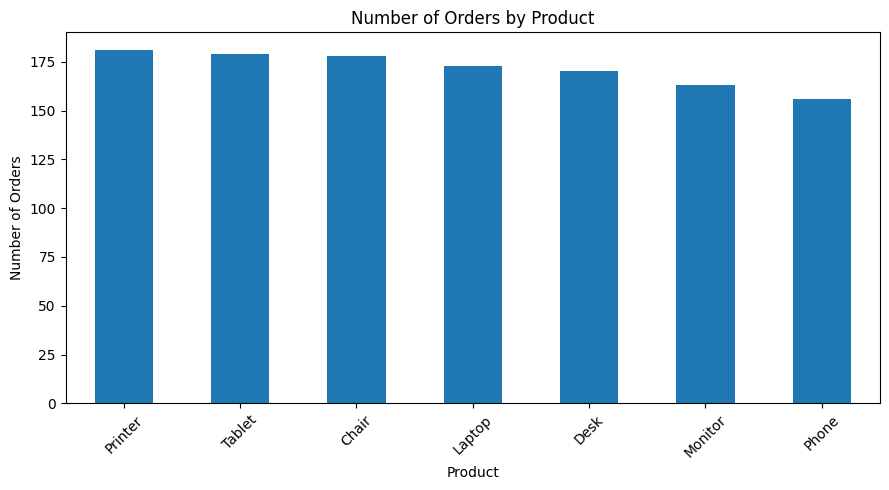

In [29]:

# Product analysis

print("Number of orders for each product:")
display(df['Product'].value_counts())

# Average order value by product
print("\nAverage order value by product:")
display(
    df.groupby('Product')['TotalPrice']
      .mean()
      .sort_values(ascending=False)
      .round(2)
)

# Bar chart of order counts by product
import matplotlib.pyplot as plt

df['Product'].value_counts().plot(kind='bar', figsize=(9, 5))

plt.title('Number of Orders by Product')
plt.xlabel('Product')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Number_of_Orders,Total_Order_Value
Month,,
2023-01,47,56685.75
2023-02,37,40117.66
2023-03,43,48609.37
2023-04,31,27751.71
2023-05,49,63836.84
2023-06,45,49500.19
2023-07,44,42820.66
2023-08,51,54352.14
2023-09,29,29526.67


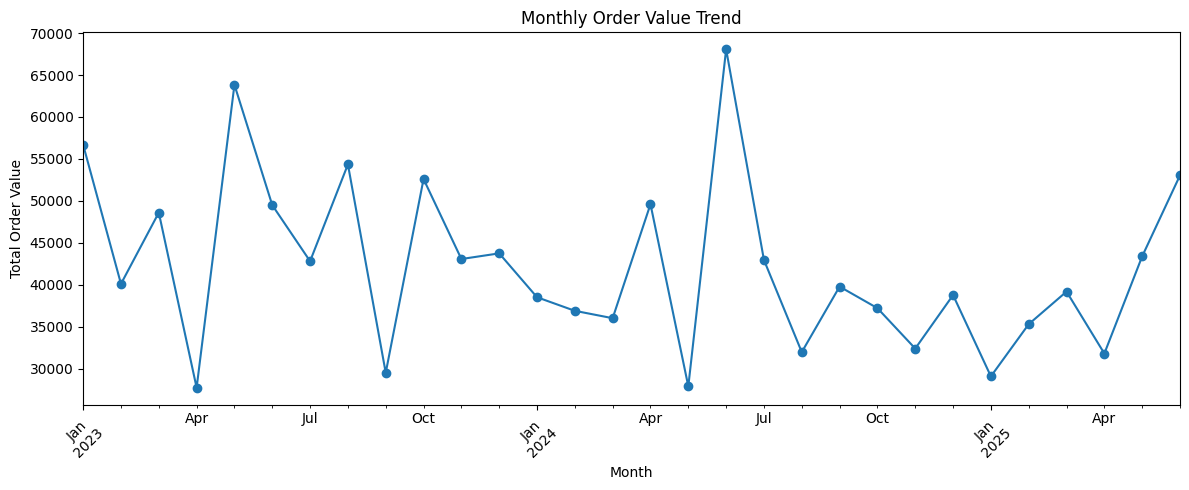

In [30]:

# Monthly trend analysis

df['Date'] = pd.to_datetime(df['Date'])

df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby('Month').agg(
    Number_of_Orders=('OrderID', 'count'),
    Total_Order_Value=('TotalPrice', 'sum')
)

display(monthly_sales)

# Plot monthly order value
monthly_sales['Total_Order_Value'].plot(
    figsize=(12, 5),
    marker='o'
)

plt.title('Monthly Order Value Trend')
plt.xlabel('Month')
plt.ylabel('Total Order Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [31]:
# Detect outliers using the IQR method

Q1 = df['TotalPrice'].quantile(0.25)
Q3 = df['TotalPrice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['TotalPrice'] < lower_limit) |
    (df['TotalPrice'] > upper_limit)
]

print("Lower limit:", round(lower_limit, 2))
print("Upper limit:", round(upper_limit, 2))
print("Number of outliers:", len(outliers))

display(outliers[['OrderID', 'Product', 'TotalPrice']])

Lower limit: -1341.41
Upper limit: 3330.41
Number of outliers: 8


,OrderID,Product,TotalPrice
107,ORD200107,Printer,3353.75
326,ORD200326,Laptop,3352.40
328,ORD200328,Tablet,3370.20
469,ORD200469,Chair,3384.90
632,ORD200632,Laptop,3390.80
789,ORD200789,Tablet,3456.40
1065,ORD201065,Printer,3334.00
1122,ORD201122,Monitor,3390.95


In [32]:
# Final EDA summary

print("Total orders:", len(df))
print("Number of products:", df['Product'].nunique())
print("Mean order value:", round(df['TotalPrice'].mean(), 2))
print("Median order value:", round(df['TotalPrice'].median(), 2))
print("Highest order value:", round(df['TotalPrice'].max(), 2))
print("Lowest order value:", round(df['TotalPrice'].min(), 2))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate OrderIDs:", df['OrderID'].duplicated().sum())
print("Potential outliers:", len(outliers))

Total orders: 1200
Number of products: 7
Mean order value: 1053.97
Median order value: 823.62
Highest order value: 3456.4
Lowest order value: 11.39
Missing values: 0
Duplicate OrderIDs: 0
Potential outliers: 8


In [33]:
# Google Colab users: upload your cleaned Excel workbook when prompted.
from pathlib import Path
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = next(iter(uploaded.keys()))
except ImportError:
    DATA_PATH = "DecodeLabs_Project1_Cleaned.xlsx"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if not Path(DATA_PATH).exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Upload the cleaned dataset or update DATA_PATH."
    )

df = pd.read_excel(DATA_PATH)
# Remove accidental whitespace around column headings, e.g. 'Duplicate OrderID '.
df.columns = df.columns.astype(str).str.strip()

# Excel date cells can be imported as datetimes or as numeric serial dates.
if pd.api.types.is_numeric_dtype(df["Date"]):
    df["Date"] = pd.to_datetime("1899-12-30") + pd.to_timedelta(df["Date"], unit="D")
else:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())


KeyboardInterrupt: 

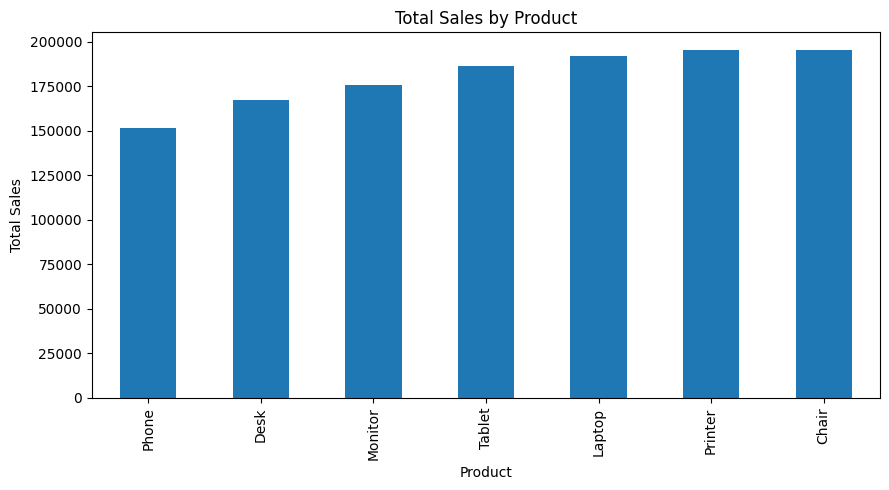

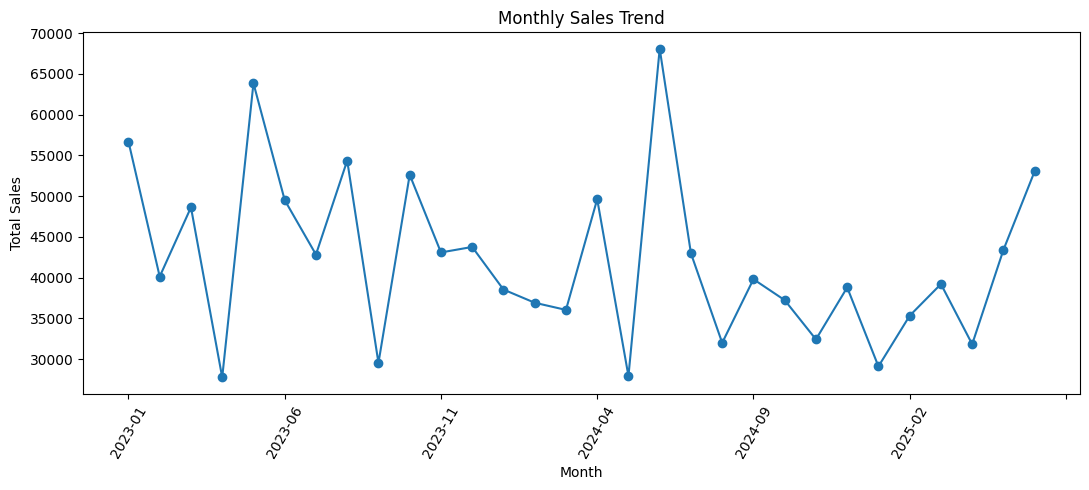

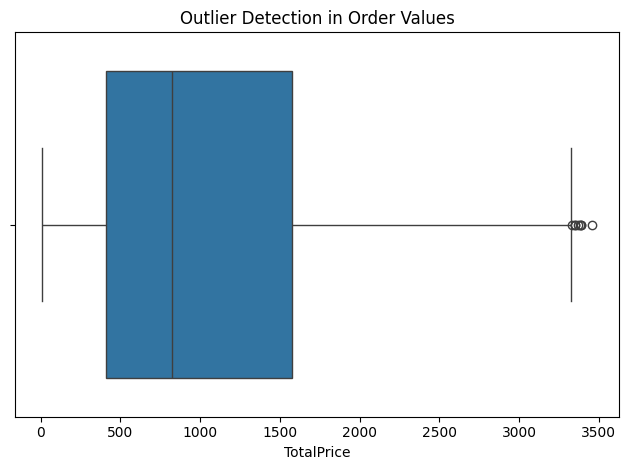

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Graph 1: Sales by product
df.groupby("Product")["TotalPrice"].sum().sort_values().plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Total Sales by Product")
plt.ylabel("Total Sales")
plt.xlabel("Product")
plt.tight_layout()
plt.show()

# Graph 2: Monthly sales trend
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
monthly = df.dropna(subset=["Date"]).groupby(
    df.dropna(subset=["Date"])["Date"].dt.to_period("M")
)["TotalPrice"].sum()

monthly.index = monthly.index.astype(str)
monthly.plot(figsize=(11, 5), marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Graph 3: Order value outliers
sns.boxplot(x=df["TotalPrice"])
plt.title("Outlier Detection in Order Values")
plt.tight_layout()
plt.show()


## 1. Check data quality

In [ ]:
quality = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
})
display(quality)

print("Duplicate full rows:", df.duplicated().sum())
print("Duplicate OrderID values:", df["OrderID"].duplicated().sum())
print("Unique customers:", df["CustomerID"].nunique())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

print("Duplicate OrderID flag values:")
display(df["Duplicate OrderID"].value_counts(dropna=False).to_frame("Count"))
print("PriceCheck values:")
display(df["PriceCheck"].value_counts(dropna=False).to_frame("Count"))

calculated = df["Quantity"] * df["UnitPrice"]
print("Rows where TotalPrice differs from Calculated TotalPrice by more than 0.01:",
      ((df["TotalPrice"] - df["Calculated TotalPrice"]).abs() > 0.01).sum())
print("Rows where Quantity × UnitPrice differs from Calculated TotalPrice by more than 0.01:",
      ((calculated - df["Calculated TotalPrice"]).abs() > 0.01).sum())


,Data type,Missing values
OrderID,object,0
Date,datetime64[ns],0
CustomerID,object,0
Product,object,0
Quantity,int64,0
UnitPrice,float64,0
ShippingAddress,object,0
PaymentMethod,object,0
OrderStatus,object,0
TrackingNumber,object,0


Duplicate full rows: 0
Duplicate OrderID values: 0
Unique customers: 1189
Date range: 2023-01-01 to 2025-06-30
Duplicate OrderID flag values:


,Count
Duplicate OrderID,
False,1200


PriceCheck values:


,Count
PriceCheck,
Correct,1200


Rows where TotalPrice differs from Calculated TotalPrice by more than 0.01: 0
Rows where Quantity × UnitPrice differs from Calculated TotalPrice by more than 0.01: 0


## 2. Descriptive statistics

In [ ]:
numeric_cols = df.select_dtypes(include="number").columns
summary = df[numeric_cols].describe().T
summary["median"] = df[numeric_cols].median()
summary["count_non_null"] = df[numeric_cols].count()
display(summary.round(2))

print("Number of orders:", df["OrderID"].count())
print("Total recorded order value:", round(df["TotalPrice"].sum(), 2))
print("Mean TotalPrice:", round(df["TotalPrice"].mean(), 2))
print("Median TotalPrice:", round(df["TotalPrice"].median(), 2))
print("Total units ordered:", int(df["Quantity"].sum()))


,count,mean,std,min,25%,50%,75%,max,median,count_non_null
Quantity,1200.0,2.95,1.41,1.00,2.00,3.00,4.00,5.00,3.00,1200
UnitPrice,1200.0,356.41,197.18,11.39,186.06,364.21,521.57,699.93,364.21,1200
ItemsInCart,1200.0,5.48,2.28,1.00,4.00,5.00,7.00,10.00,5.00,1200
TotalPrice,1200.0,1053.97,819.86,11.39,410.52,823.62,1578.48,3456.40,823.62,1200
Calculated TotalPrice,1200.0,1053.97,819.86,11.39,410.52,823.62,1578.48,3456.40,823.62,1200


Number of orders: 1200
Total recorded order value: 1264761.96
Mean TotalPrice: 1053.97
Median TotalPrice: 823.62
Total units ordered: 3535


## 3. Categorical analysis

In [ ]:
for column in ["Product", "PaymentMethod", "OrderStatus", "CouponCode", "ReferralSource"]:
    print(f"\n{column} — order count:")
    display(df[column].value_counts(dropna=False).rename("Count").to_frame())

product_summary = df.groupby("Product").agg(
    Orders=("OrderID", "count"),
    Units=("Quantity", "sum"),
    Recorded_Order_Value=("TotalPrice", "sum"),
    Average_Order_Value=("TotalPrice", "mean"),
).sort_values("Recorded_Order_Value", ascending=False)
display(product_summary.round(2))



Product — order count:


,Count
Product,
Printer,181
Tablet,179
Chair,178
Laptop,173
Desk,170
Monitor,163
Phone,156



PaymentMethod — order count:


,Count
PaymentMethod,
Online,258
Cash,246
Credit Card,234
Debit Card,232
Gift Card,230



OrderStatus — order count:


...


CouponCode — order count:


,Count
CouponCode,
FREESHIP,313
No Coupon,309
WINTER15,292
SAVE10,286



ReferralSource — order count:


,Count
ReferralSource,
Instagram,259
Email,250
Google,241
Facebook,228
Referral,222


,Orders,Units,Recorded_Order_Value,Average_Order_Value
Product,,,,
Chair,178,562,195620.11,1098.99
Printer,181,542,195612.61,1080.73
Laptop,173,535,192126.56,1110.56
Tablet,179,497,186568.95,1042.28
Monitor,163,480,175651.41,1077.62
Desk,170,508,167459.93,985.06
Phone,156,411,151722.39,972.58


## 4. Visualize product, order status, and time patterns

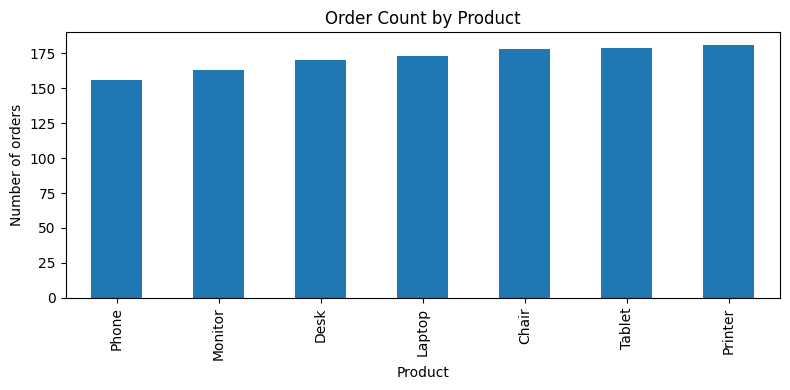

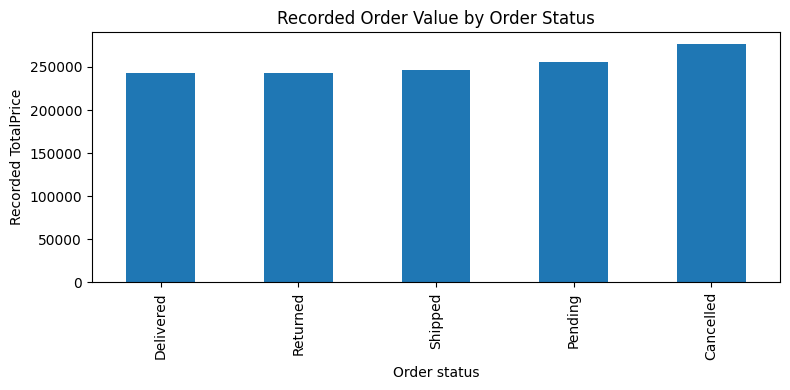

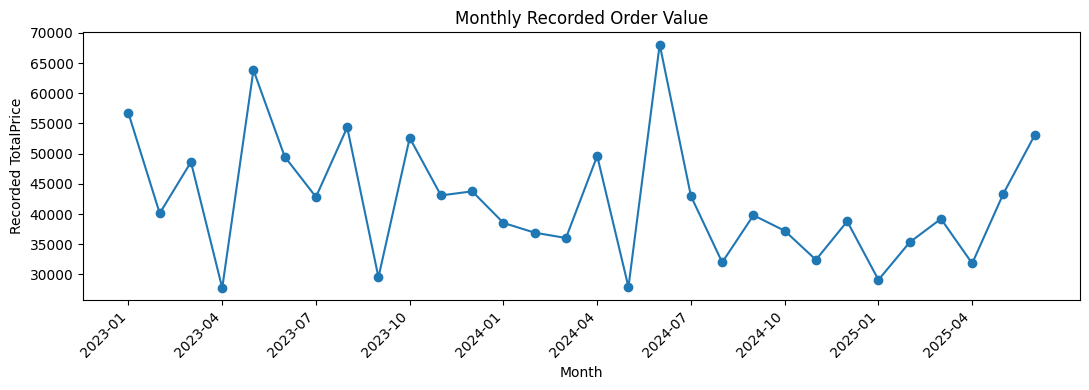

,Month,Orders,Recorded_Order_Value
17,2024-06,53,68068.54
4,2023-05,49,63836.84
0,2023-01,47,56685.75
7,2023-08,51,54352.14
29,2025-06,49,53047.40
9,2023-10,47,52607.85
15,2024-04,50,49613.14
5,2023-06,45,49500.19
2,2023-03,43,48609.37
11,2023-12,46,43754.73


In [ ]:
# Orders by product
(df["Product"].value_counts().sort_values()).plot(kind="bar", figsize=(8, 4), title="Order Count by Product")
plt.xlabel("Product"); plt.ylabel("Number of orders"); plt.tight_layout(); plt.show()

# Recorded order value by status — not the same as realized revenue.
(df.groupby("OrderStatus")["TotalPrice"].sum().sort_values()).plot(kind="bar", figsize=(8, 4), title="Recorded Order Value by Order Status")
plt.xlabel("Order status"); plt.ylabel("Recorded TotalPrice"); plt.tight_layout(); plt.show()

monthly = (df.assign(Month=df["Date"].dt.to_period("M").astype(str))
           .groupby("Month")
           .agg(Orders=("OrderID", "count"), Recorded_Order_Value=("TotalPrice", "sum"))
           .reset_index())
plt.figure(figsize=(11, 4))
plt.plot(monthly["Month"], monthly["Recorded_Order_Value"], marker="o")
plt.title("Monthly Recorded Order Value"); plt.xlabel("Month"); plt.ylabel("Recorded TotalPrice")
plt.xticks(range(0, len(monthly), 3), monthly["Month"].iloc[::3], rotation=45, ha="right")
plt.tight_layout(); plt.show()
display(monthly.sort_values("Recorded_Order_Value", ascending=False).head(10))


## 5. Detect potential outliers using the IQR method

Q1=410.52; median=823.62; Q3=1578.47; IQR=1167.95
Lower fence=-1341.41; upper fence=3330.41
Potential outlier records: 8


,OrderID,Date,Product,Quantity,UnitPrice,OrderStatus,TotalPrice,PriceCheck
107,ORD200107,2023-03-27,Printer,5,670.75,Shipped,3353.75,Correct
326,ORD200326,2024-07-01,Laptop,5,670.48,Returned,3352.40,Correct
328,ORD200328,2023-02-28,Tablet,5,674.04,Cancelled,3370.20,Correct
469,ORD200469,2023-11-26,Chair,5,676.98,Cancelled,3384.90,Correct
632,ORD200632,2023-05-02,Laptop,5,678.16,Delivered,3390.80,Correct
789,ORD200789,2023-08-17,Tablet,5,691.28,Delivered,3456.40,Correct
1065,ORD201065,2023-10-30,Printer,5,666.80,Delivered,3334.00,Correct
1122,ORD201122,2023-06-07,Monitor,5,678.19,Returned,3390.95,Correct


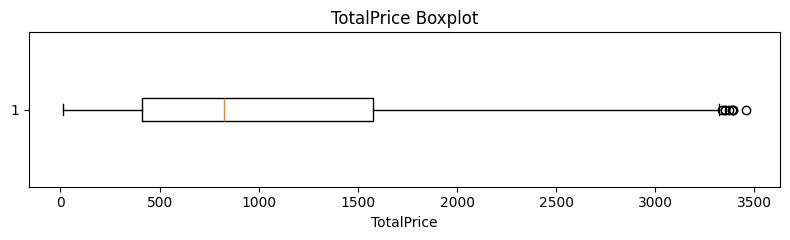

In [ ]:
column = "TotalPrice"
q1, q3 = df[column].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

print(f"Q1={q1:.2f}; median={df[column].median():.2f}; Q3={q3:.2f}; IQR={iqr:.2f}")
print(f"Lower fence={lower_bound:.2f}; upper fence={upper_bound:.2f}")
print("Potential outlier records:", len(outliers))
display(outliers[["OrderID", "Date", "Product", "Quantity", "UnitPrice", "OrderStatus", "TotalPrice", "PriceCheck"]])

plt.figure(figsize=(8, 2.5))
plt.boxplot(df[column].dropna(), vert=False)
plt.title("TotalPrice Boxplot"); plt.xlabel("TotalPrice"); plt.tight_layout(); plt.show()

# IQR flags identify unusually high/low values; they do not prove an error.


## 6. Correlation analysis

,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.000,0.015,0.650,0.615
UnitPrice,0.015,1.000,0.001,0.717
ItemsInCart,0.650,0.001,1.000,0.393
TotalPrice,0.615,0.717,0.393,1.000


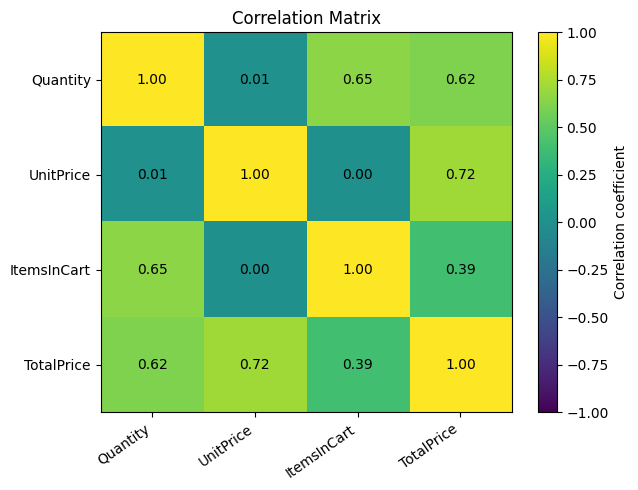

Correlation does not prove causation. TotalPrice is calculated from Quantity × UnitPrice, so
a positive association with Quantity and UnitPrice is expected.


In [ ]:
numeric_for_corr = df[["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]]
corr = numeric_for_corr.corr()
display(corr.round(3))

plt.figure(figsize=(6.5, 5))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation Matrix"); plt.tight_layout(); plt.show()

print("Correlation does not prove causation. TotalPrice is calculated from Quantity × UnitPrice, so")
print("a positive association with Quantity and UnitPrice is expected.")


## 7. Key findings and conclusion

In [ ]:
top_product_value = df.groupby("Product")["TotalPrice"].sum().idxmax()
top_product_orders = df["Product"].value_counts().idxmax()
top_payment = df["PaymentMethod"].value_counts().idxmax()
top_status = df["OrderStatus"].value_counts().idxmax()
top_referral = df["ReferralSource"].value_counts().idxmax()
peak_month = monthly.loc[monthly["Recorded_Order_Value"].idxmax()]

print(f"Top product by recorded order value: {top_product_value}")
print(f"Most frequently ordered product: {top_product_orders}")
print(f"Most common payment method: {top_payment}")
print(f"Most common order status: {top_status}")
print(f"Most common referral source: {top_referral}")
print(f"Highest recorded-order-value month: {peak_month['Month']} ({peak_month['Recorded_Order_Value']:.2f})")
print(f"Total recorded order value: {df['TotalPrice'].sum():.2f}")
print(f"Mean TotalPrice: {df['TotalPrice'].mean():.2f}; median TotalPrice: {df['TotalPrice'].median():.2f}")
print(f"Potential IQR outliers: {len(outliers)}")

print("\nConclusion:")
print("The cleaned dataset contains no missing values, duplicate order IDs, or price-check failures. ")
print("The categorical summaries and monthly chart show how recorded order value and order counts vary. ")
print("Potential outliers should be reviewed with business context before exclusion. ")
print("Because Cancelled and Returned orders are included, do not label the total as completed sales revenue.")


Top product by recorded order value: Chair
Most frequently ordered product: Printer
Most common payment method: Online
Most common order status: Cancelled
Most common referral source: Instagram
Highest recorded-order-value month: 2024-06 (68068.54)
Total recorded order value: 1264761.96
Mean TotalPrice: 1053.97; median TotalPrice: 823.62
Potential IQR outliers: 8

Conclusion:
The cleaned dataset contains no missing values, duplicate order IDs, or price-check failures. 
The categorical summaries and monthly chart show how recorded order value and order counts vary. 
Potential outliers should be reviewed with business context before exclusion. 
Because Cancelled and Returned orders are included, do not label the total as completed sales revenue.
